# Assignment 5 - ANOVA and Simple Linear Regression

Group members: Sebastian Bartko, Mariia Moskovko, Matej Palas, Sebastian Halas

Table of contents
1. Part 1 - Composite strength across curing methods
2. Part 2 - Diagnostics, post-hoc comparisons, and magnitude
3. Part 3 - Pump flow and energy use
4. Part 4 - Regression diagnostics and prediction
5. Part 5 - AI-use and conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import probplot, pearsonr
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

In [2]:
strengths = pd.read_csv("data/assignment05_composite_strength.csv")
pump = pd.read_csv("data/assignment05_pump_energy.csv")

display(strengths.head())
display(strengths["curing_method"].unique())
display(pump.head())

,specimen_id,curing_method,strength_mpa
0,1,ambient,53.09
1,2,ambient,48.91
2,3,ambient,55.11
3,4,ambient,54.53
4,5,ambient,57.05


<StringArray>
['ambient', 'thermal', 'uv', 'hybrid']
Length: 4, dtype: str

,run_id,flow_l_min,energy_kwh
0,1,22.70,18.110
1,2,22.93,13.534
2,3,23.42,15.300
3,4,24.35,17.677
4,5,25.13,18.420


# Part 1 - Composite strength across curing methods

The file contains independent composite specimens cured by four methods. The response is `strength_mpa` and the factor is `curing_method`.

**a.** Identify the population, observational unit, response, factor, and factor levels. Explain what additional design information would be needed for a causal claim about curing method.

- **Population:** all composite specimens of this kind that could be made and cured with one of the four methods. We only have a sample of 96 of them.
- **Observational unit:** one specimen. Each row in the data is one specimen.
- **Response:** `strength_mpa`, how strong the specimen is, in MPa. This is what we measure.
- **Factor:** `curing_method`, the way the specimen was cured (hardened). This is what we think might change the strength.
- **Factor levels:** the four methods: ambient, thermal, uv and hybrid.

**Can we say the method causes the strength difference?** Not from the data alone. We would need to know how the study was done:
- Was it random which specimen got which method? If for example all hybrid specimens came from a better batch of material, the batch could be the real reason.
- Were all specimens made from the same material, with the same size, and tested on the same machine?
- Were the specimens tested in a random order, so that things like machine wear do not affect one group more than another?
- Was each specimen cured on its own, and not several together in one oven run?

Only if the answer to these is yes can we put a difference in strength down to the curing method.

**b.** Report group sample sizes, means, and sample standard deviations. Create side-by-side boxplots and describe between-group differences and within-group variation.

In [3]:
order = ["ambient", "thermal", "uv", "hybrid"]
summary = strengths.groupby("curing_method")["strength_mpa"].agg(["count", "mean", "std"]).loc[order]
summary.columns = ["n", "mean (MPa)", "sd (MPa)"]
display(summary.round(2))
print(f"largest sd / smallest sd = {summary['sd (MPa)'].max() / summary['sd (MPa)'].min():.2f}")

,n,mean (MPa),sd (MPa)
curing_method,,,
ambient,24,52.18,5.55
thermal,24,55.82,4.09
uv,24,55.42,3.44
hybrid,24,63.57,6.20


largest sd / smallest sd = 1.80


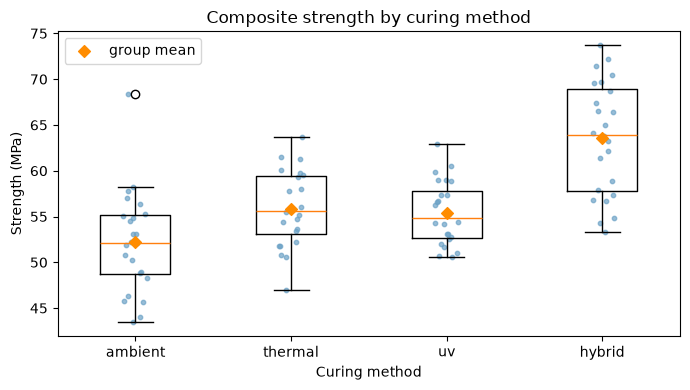

In [4]:
groups = [strengths.loc[strengths["curing_method"] == g, "strength_mpa"] for g in order]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(groups, tick_labels=order)
for i, g in enumerate(groups, start=1):
    ax.scatter(np.full(len(g), i) + np.random.uniform(-0.08, 0.08, len(g)), g, s=10, color="#6CA2C6", alpha=0.7)
ax.scatter(range(1, 5), summary["mean (MPa)"], marker="D", color="#FF8C00", zorder=3, label="group mean")
ax.set_xlabel("Curing method")
ax.set_ylabel("Strength (MPa)")
ax.set_title("Composite strength by curing method")
ax.legend()
plt.tight_layout()
plt.show()

Every method has 24 specimens.

**Differences between the methods:** hybrid gives the strongest specimens on average (63.6 MPa). Ambient is the weakest (52.2 MPa). Thermal (55.8 MPa) and uv (55.4 MPa) are in between and almost the same.

**Differences inside each method:** specimens with the same method are not all equally strong. The standard deviation (how much the values typically differ from their group average) goes from 3.4 MPa for uv to 6.2 MPa for hybrid. Because of this the boxes overlap quite a lot, except hybrid, which sits clearly higher than the others. One ambient specimen (68.4 MPa) is much stronger than the rest of its group.

**c.** State the one-way ANOVA hypotheses. Explain why a collection of unadjusted pairwise t-tests is a poor default.

ANOVA (analysis of variance) is a test that checks if several groups have the same average.

- H0: all four methods give the same average strength.
- H1: at least one method gives a different average strength.

We use a 5% significance level (alpha = 0.05).

**Why not just compare each pair with a t-test?** With 4 methods there are 6 pairs to compare. Every t-test has a 5% risk of finding a difference that is not really there. If we do 6 tests, these risks add up, and the chance of at least one false finding becomes about 26% (1 - 0.95^6). ANOVA does one single test for all groups at once, so the risk stays at 5%.

**d.** Fit the classical one-way model and produce an ANOVA table. Report sums of squares, degrees of freedom, mean squares, F, and p, and explain what the F ratio compares.

In [5]:
model = ols("strength_mpa ~ C(curing_method)", data=strengths).fit()
tbl = anova_lm(model, typ=2)
tbl["mean_sq"] = tbl["sum_sq"] / tbl["df"]
tbl = tbl[["sum_sq", "df", "mean_sq", "F", "PR(>F)"]]
display(tbl)

ss_between = tbl.loc["C(curing_method)", "sum_sq"]
ss_within = tbl.loc["Residual", "sum_sq"]
print(f"SS total = {ss_between + ss_within:.2f}")
print(f"F = {tbl.loc['C(curing_method)', 'F']:.2f}, p = {tbl.loc['C(curing_method)', 'PR(>F)']:.3g}")

,sum_sq,df,mean_sq,F,PR(>F)
C(curing_method),1682.080428,3.0,560.693476,22.942315,3.554955e-11
Residual,2248.412996,92.0,24.439272,NaN,NaN


SS total = 3930.49
F = 22.94, p = 3.55e-11


The ANOVA splits the total variation in strength into two parts:
- **Between groups:** how far the four group averages are from the overall average. This is the part that comes from the curing method.
- **Within groups:** how far each specimen is from its own group average. This is the random variation between specimens (noise).

| Source | Sum of squares (SS) | df | Mean square (MS) | F | p |
|---|---|---|---|---|---|
| Between groups (curing method) | 1682.1 | 3 | 560.7 | 22.94 | 3.6e-11 |
| Within groups (residual) | 2248.4 | 92 | 24.4 | | |
| Total | 3930.5 | 95 | | | |

- **SS (sum of squares):** the squared distances added up. A bigger number means more variation.
- **df (degrees of freedom):** between = number of groups - 1 = 3. Within = number of specimens - number of groups = 96 - 4 = 92.
- **MS (mean square):** SS / df, so a kind of average variation per degree of freedom.

**F** = MS between / MS within = 560.7 / 24.4 = 22.9. It compares how different the methods are with how much specimens normally vary. If the method did not matter, F would be around 1. Here the differences between the methods are about 23 times bigger than what random variation alone would give.

**p = 3.6e-11** (0.000000000036). This is the chance of getting an F this large if all four methods really had the same average. It is far below 0.05, so we reject H0: at least one curing method gives a different average strength. Which methods differ is checked in Part 2.